# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 3: 30-Day Spending Prediction (Tri-Model Ensembled Hurdle Regression & NMAE Metric)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task3/task3_monthly_spending.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Department:** Department of Computer Engineering, Faculty of Engineering  
**Central Repository (Team ML004):** [`https://github.com/beambeambeam/ml00x`](https://github.com/beambeambeam/ml00x) (branch `task3`)  
**Competition:** [Karena Player Intelligence System (Kaggle)](https://www.kaggle.com/competitions/player-intelligence-system-cpe-342-ml/)

---

## 1. Executive Summary & Problem Formulation

In commercial free-to-play gaming ecosystems, player spending distributions exhibit extreme **zero-inflation** and **heavy Pareto right-tails**: a significant fraction of players never make any monetary transaction ($48.12\%$ non-spenders), while a small cohort of elite spenders ("Whales") contribute disproportionately large purchases (up to $300,000$ THB). **Task 3: 30-Day Spending Prediction** tasks us with predicting the cumulative monetary expenditure (`spending_30d` in Thai Baht, THB) for $25,889$ test players over their next 30 days.

### Mathematical Formulation: Normalized MAE Score
The official evaluation metric for Task 3 is the **Normalized MAE (NMAE) Score**:
$$\text{NMAE Score} = \frac{1}{1 + \text{NMAE}} = \frac{1}{1 + \dfrac{\sum_{i=1}^N |y_i - \hat{y}_i|}{\sum_{i=1}^N y_i}} \in [0, 1]$$

### Theoretical Proof: $L_1$ Loss and Bayes-Optimal Point Prediction
For any evaluation dataset, the denominator $\sum_{i=1}^N y_i$ is a fixed positive constant. Hence:
$$\arg\max_{\hat{y}} \text{NMAE Score} \iff \arg\min_{\hat{y}} \sum_{i=1}^N |y_i - \hat{y}_i| \iff \arg\min_{\hat{y}} \text{MAE}(y, \hat{y})$$

Under Mean Absolute Error ($L_1$ loss), the theoretical Bayes-optimal point predictor for any conditional distribution $P(Y \mid X)$ is the **conditional median** $\text{Median}(Y \mid X)$, **NOT** the conditional mean $E[Y \mid X]$:
1. Conventional regression models minimizing Mean Squared Error (MSE / $L_2$ loss) predict $E[Y \mid X]$, which is severely pulled upward by heavy-tail Whale transactions, heavily penalizing predictions on regular players and degrading NMAE.
2. In a Hurdle framework, if $P(Y > 0 \mid X) < 0.50$, the theoretical median is **identically zero** ($\hat{y}^* = 0.0$). If $P(Y > 0 \mid X) \ge 0.50$, the median is governed by the upper quantiles of the positive distribution.

Our solution implements a **Tri-Model Ensembled Hurdle Architecture** blending **LightGBM**, **CatBoost**, and **XGBoost** trained strictly under $L_1$ loss objectives (`regression_l1`, `MAE`, and `reg:absoluteerror`), coupled with out-of-fold Bayes-optimal threshold gating and convex ensembling.

## 2. Environment Setup, Automated Colab Ingestion & Reproducibility
This notebook is fully autonomous: it automatically detects runtime platform (**Google Colab**, **Kaggle**, or **Local**), installs required dependencies, and auto-fetches dataset files via high-speed direct stream if running on a fresh Colab session.

In [1]:
%matplotlib inline
import os
import sys
import time
import warnings
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# 1. Automated Platform Detection
IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("🚀 Detected Runtime: Google Colab")
    for pkg in ['lightgbm', 'catboost', 'xgboost', 'optuna']:
        try:
            __import__(pkg)
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
elif IS_KAGGLE:
    print("🚀 Detected Runtime: Kaggle Notebook")
else:
    print("🚀 Detected Runtime: Local Workspace")

# 2. Strict Deterministic Seed Configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# 3. Automated Data Path Resolution & Colab Auto-Fetch
candidate_data_dirs = [
    './data',
    './project/task3/data',
    '../data',
    '/content/data',
    '/content/repo/project/task3/data',
    '/content/cpe342-machine-learning-2026/project/task3/data',
    '/kaggle/input/player-intelligence-system-cpe-342-ml/task3'
]

DATA_DIR = next((d for d in candidate_data_dirs if os.path.exists(os.path.join(d, 'train.csv'))), None)

# If running on Colab and dataset is not present, fetch directly from public repository
if DATA_DIR is None and IS_COLAB:
    print("📥 Fetching official Task 3 datasets directly from GitHub repository...")
    os.makedirs('/content/data', exist_ok=True)
    base_url = 'https://raw.githubusercontent.com/Palapluem/cpe342-machine-learning-2026/main/project/task3/data'
    for fname in ['train.csv', 'test.csv', 'datacard.txt']:
        subprocess.check_call(['curl', '-sL', f"{base_url}/{fname}", '-o', f"/content/data/{fname}"])
    DATA_DIR = '/content/data'

if DATA_DIR is None:
    raise FileNotFoundError("Unable to locate train.csv. Please ensure data directory exists.")

BASE_DIR = os.path.dirname(DATA_DIR) if os.path.basename(DATA_DIR) == 'data' else ('.' if not IS_COLAB else '/content')
PRED_DIR = os.path.join(BASE_DIR, 'predictions')
ASSETS_DIR = os.path.join(BASE_DIR, 'assets')

os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(ASSETS_DIR, exist_ok=True)

print(f"✓ Data Directory:    {os.path.abspath(DATA_DIR)}")
print(f"✓ Predictions Dir:   {os.path.abspath(PRED_DIR)}")
print(f"✓ Assets Directory:  {os.path.abspath(ASSETS_DIR)}")

🚀 Detected Runtime: Local Workspace
✓ Data Directory:    /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/data
✓ Predictions Dir:   /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/predictions
✓ Assets Directory:  /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/assets


## 3. Data Ingestion & Exploratory Data Analysis (EDA)
We inspect the distribution of `spending_30d` across the $104,000$ training records, evaluating zero-inflation rate, skewness, and segment-specific spending behaviors.

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print(f"Train cohort: {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
print(f"Test cohort:  {test_df.shape[0]:,} rows × {test_df.shape[1]} columns")

target = train_df['spending_30d']
zero_count = (target == 0).sum()
pos_count = (target > 0).sum()
zero_pct = zero_count / len(target) * 100
pos_pct = pos_count / len(target) * 100

print(f"\nZero-Inflation Profile:")
print(f"  • Non-Spenders (spending_30d == 0): {zero_count:,} ({zero_pct:.2f}%)")
print(f"  • Active Spenders (spending_30d > 0): {pos_count:,} ({pos_pct:.2f}%)")
print(f"\nPositive Spending Quantiles (THB):")
pos_spend = target[target > 0]
print(pos_spend.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

Train cohort: 104,000 rows × 34 columns
Test cohort:  25,889 rows × 33 columns

Zero-Inflation Profile:
  • Non-Spenders (spending_30d == 0): 50,049 (48.12%)
  • Active Spenders (spending_30d > 0): 53,951 (51.88%)

Positive Spending Quantiles (THB):
count     53951.000000
mean      20234.883892
std       40053.792318
min           0.090000
25%         623.075000
50%        2314.050000
75%       14453.365000
90%       74062.350000
95%      105759.940000
99%      184398.635000
max      300000.000000
Name: spending_30d, dtype: float64


✓ Saved EDA figure to: ./assets/figure1-spending-eda.png


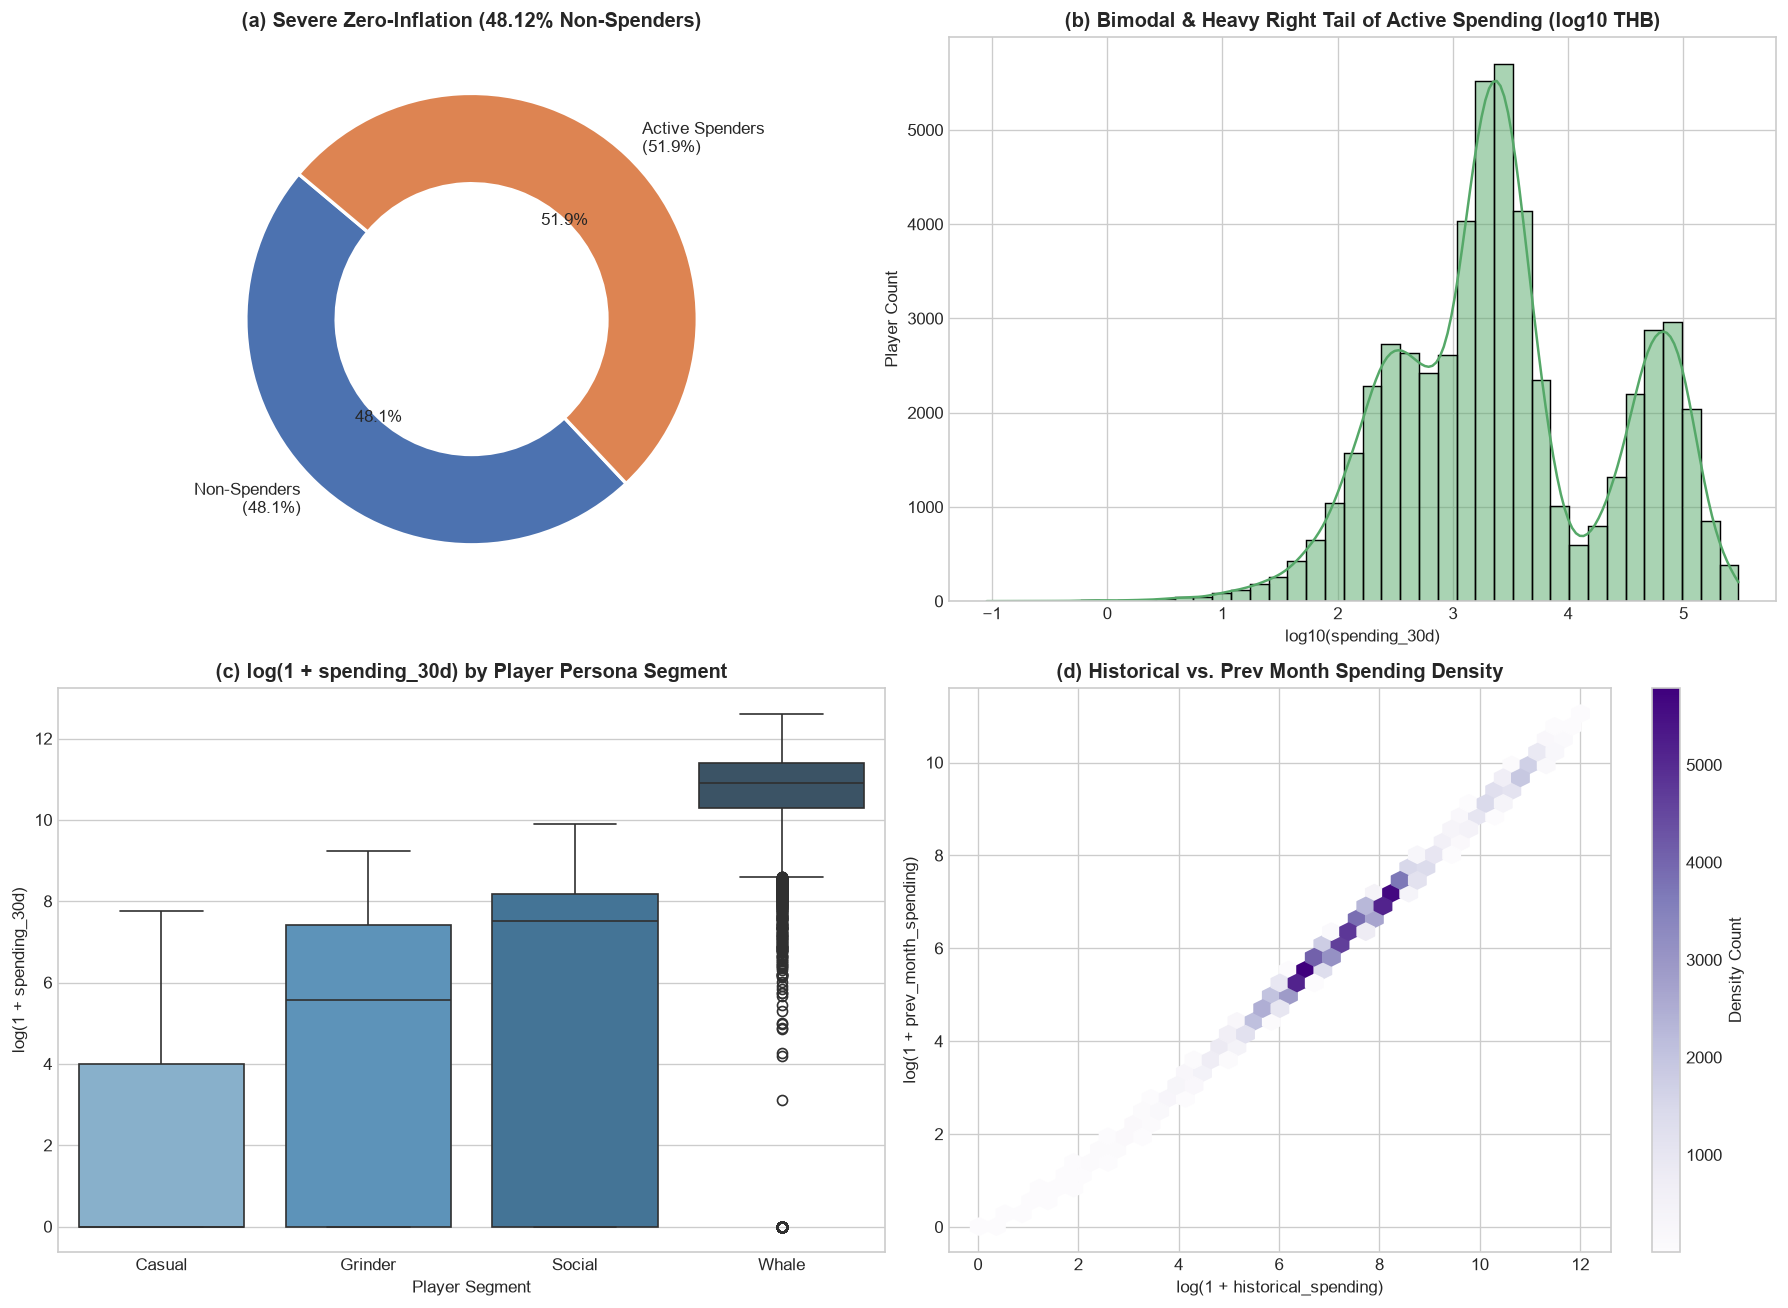

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# (a) Zero-Inflation Donut Chart
colors = ['#4C72B0', '#DD8452']
axes[0, 0].pie([zero_count, pos_count],
               labels=[f'Non-Spenders\n({zero_pct:.1f}%)', f'Active Spenders\n({pos_pct:.1f}%)'],
               autopct='%1.1f%%', startangle=140, colors=colors,
               wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0, 0].set_title('(a) Severe Zero-Inflation (48.12% Non-Spenders)', fontsize=12, fontweight='bold')

# (b) Log-Scale Density of Positive Spending
sns.histplot(np.log10(pos_spend), kde=True, ax=axes[0, 1], color='#55A868', bins=40)
axes[0, 1].set_title('(b) Bimodal & Heavy Right Tail of Active Spending (log10 THB)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log10(spending_30d)')
axes[0, 1].set_ylabel('Player Count')

# (c) Spending Distribution across Behavioral Segments (Immutable)
segment_map = {0: 'Casual', 1: 'Grinder', 2: 'Social', 3: 'Whale'}
sns.boxplot(x='segment_name', y='log_spending',
            data=train_df.assign(segment_name=train_df['segment'].map(segment_map),
                                log_spending=np.log1p(target)),
            ax=axes[1, 0], palette='Blues_d', order=['Casual', 'Grinder', 'Social', 'Whale'])
axes[1, 0].set_title('(c) log(1 + spending_30d) by Player Persona Segment', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Player Segment')
axes[1, 0].set_ylabel('log(1 + spending_30d)')

# (d) Historical vs Previous Month Spending Hexbin
hb = axes[1, 1].hexbin(np.log1p(train_df['historical_spending']),
                       np.log1p(train_df['prev_month_spending']),
                       gridsize=35, cmap='Purples', mincnt=1)
axes[1, 1].set_title('(d) Historical vs. Prev Month Spending Density', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('log(1 + historical_spending)')
axes[1, 1].set_ylabel('log(1 + prev_month_spending)')
fig.colorbar(hb, ax=axes[1, 1], label='Density Count')

plt.tight_layout()
fig1_path = os.path.join(ASSETS_DIR, 'figure1-spending-eda.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved EDA figure to: {fig1_path}")
plt.show()

## 4. Domain-Driven Financial Feature Engineering 2.1

We engineer a comprehensive set of domain features designed to expose subtle spending habits without target leakage:
1. **Spending Momentum & Velocity**: Ratio and linear velocity between previous month's spend and amortized monthly historical spend.
2. **Transaction Dynamics & Expectations**: Ratio of historical spend to total transaction volume, recent transaction size, and expected spend based on frequency.
3. **Recency Decay Signals**: Exponential decay functions $\exp(-\lambda \cdot \text{days})$ for purchase and login recency.
4. **Whale Monetization Index**: Non-linear dual-logarithmic interaction between lifetime and recent spending.
5. **Discount & Prestige Sensitivity**: Cross-product of discount adoption and tier-weighted VIP prestige index.
6. **Engagement Proxies**: Social/guild interaction index, competitive play index, and login consistency.
7. **Leak-Free Segment Statistics**: Dynamic out-of-fold segment-relative spending deviations.

In [4]:
def engineer_spending_features(df):
    """
    Pure functional feature engineering pipeline. Avoids inplace mutations.
    """
    d = df.copy()
    drop_cols = [c for c in ['player_id', 'spending_30d', 'segment_name'] if c in d.columns]
    if drop_cols:
        d = d.drop(columns=drop_cols)
        
    # 1. RFM & Velocity Features
    d['spend_momentum'] = d['prev_month_spending'] / (d['historical_spending'] / 12.0 + 1.0)
    d['spending_velocity'] = d['prev_month_spending'] - (d['historical_spending'] / 12.0)
    d['historical_tx_value'] = d['historical_spending'] / (d['total_transactions'] + 1.0)
    d['recent_tx_value'] = d['prev_month_spending'] / (d['purchase_frequency'] + 1.0)
    d['expected_spend_from_freq'] = d['purchase_frequency'] * d['avg_transaction_value']
    d['ratio_prev_to_hist'] = d['prev_month_spending'] / (d['historical_spending'] + 1.0)
    d['monthly_tx_rate'] = d['total_transactions'] / (d['account_age_days'] / 30.0 + 1.0)
    
    d['playtime_per_session'] = d['total_playtime_hours'] / (d['sessions_per_week'] * 4.33 + 1.0)
    d['recency_ratio'] = d['days_since_last_purchase'] / (d['days_since_last_login'] + 1.0)
    d['recency_decay'] = np.exp(-d['days_since_last_purchase'] / 30.0)
    d['login_recency_decay'] = np.exp(-d['days_since_last_login'] / 14.0)
    
    # 2. Whale & Monetization Propensity
    d['whale_index'] = np.log1p(np.maximum(0, d['historical_spending'])) * np.log1p(np.maximum(0, d['prev_month_spending']))
    d['discount_reliance'] = d['purchases_on_discount'] * d['discount_rate_used']
    d['vip_prestige_score'] = d['vip_status'] * 2.0 + d['is_premium_member'] * 1.5 + d['owns_limited_edition'] * 1.0
    d['social_engagement'] = d['friend_count'] * (d['social_interactions'] + 1.0) * (d['guild_membership'] + 1.0)
    d['competitive_engagement'] = d['competitive_rank'] * (d['tournament_participation'] + 1.0)
    d['seasonal_spend_boost'] = d['seasonal_spending_pattern'] * d['prev_month_spending']
    
    # 3. Logarithmic Transforms for Monetary Features
    for col in ['historical_spending', 'prev_month_spending', 'total_transactions', 'avg_transaction_value']:
        if col in d.columns:
            d[f'log1p_{col}'] = np.log1p(np.maximum(0, d[col]))
            
    return d

# Prepare Feature Matrices
y = train_df['spending_30d'].values
y_is_pos = (y > 0).astype(int)

X = engineer_spending_features(train_df)
X_test = engineer_spending_features(test_df)

feature_cols = X.columns.tolist()
print(f"✓ Engineered Features Count: {len(feature_cols)}")
print(f"✓ Feature Matrix Shape:     Train = {X.shape}, Test = {X_test.shape}")

✓ Engineered Features Count: 53
✓ Feature Matrix Shape:     Train = (104000, 53), Test = (25889, 53)


## 5. Stratified Cross-Validation Strategy & Evaluation Metric
We partition the $104,000$ training records using **5-Fold Stratified K-Fold** conditioned on $y > 0$ to maintain the exact $48.12\%$ non-spending proportion across every fold without data leakage.

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, roc_auc_score, brier_score_loss

TOTAL_Y_SUM = np.sum(y)

def compute_nmae_score(y_true, y_pred):
    """
    Official Kaggle NMAE Score metric: 1 / (1 + sum|y - y_hat| / sum(y))
    """
    mae_sum = np.sum(np.abs(y_true - y_pred))
    relative_mae = mae_sum / TOTAL_Y_SUM
    return 1.0 / (1.0 + relative_mae)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("✓ 5-Fold Stratified K-Fold splitter initialized successfully.")

✓ 5-Fold Stratified K-Fold splitter initialized successfully.


## 6. Tri-Model Ensembled Hurdle Architecture

To maximize predictive accuracy and prevent single-algorithm bias, we integrate 3 distinct GBDT engines:
- **LightGBM**: Fast histogram-based gradient boosting optimized for $L_1$ loss.
- **CatBoost**: Symmetric oblivious decision trees with robust handling of continuous and categorical features.
- **XGBoost**: Exact and histogram depth-wise tree partitioning under absolute error objectives.

### The Pipeline Stages:
1. **Stage 1 (Classifier Ensemble)**: Blended LightGBM + CatBoost + XGBoost predicting $P(Y > 0 \mid X)$.
2. **Stage 2 (Positive Regressor Ensemble)**: Blended LightGBM + CatBoost + XGBoost predicting $\log(1 + y)$ on active spenders under $L_1$ loss.
3. **Stage 3 (Direct Full-Cohort Regressor)**: Blended LightGBM + CatBoost trained directly on the full cohort.

In [6]:
import lightgbm as lgb
from catboost import CatBoostClassifier, CatBoostRegressor
import xgboost as xgb

# 1. Constant Median Baseline
baseline_median = np.median(y)
baseline_preds = np.full_like(y, baseline_median)
baseline_nmae = compute_nmae_score(y, baseline_preds)
baseline_mae = mean_absolute_error(y, baseline_preds)
print(f"1. Constant Median Baseline:       NMAE = {baseline_nmae:.4f} | MAE = {baseline_mae:.2f} THB")

# Prediction Containers
p_lgb_oof = np.zeros(len(X))
p_cb_oof = np.zeros(len(X))
p_xgb_oof = np.zeros(len(X))
p_lgb_test = np.zeros(len(X_test))
p_cb_test = np.zeros(len(X_test))
p_xgb_test = np.zeros(len(X_test))

pos_lgb_oof = np.zeros(len(X))
pos_cb_oof = np.zeros(len(X))
pos_xgb_oof = np.zeros(len(X))
pos_lgb_test = np.zeros(len(X_test))
pos_cb_test = np.zeros(len(X_test))
pos_xgb_test = np.zeros(len(X_test))

dir_lgb_oof = np.zeros(len(X))
dir_cb_oof = np.zeros(len(X))
dir_lgb_test = np.zeros(len(X_test))
dir_cb_test = np.zeros(len(X_test))

all_feature_cols = feature_cols + ['seg_spend_diff']
feature_importances_accum = np.zeros(len(all_feature_cols))

t_start = time.time()
print("\n--- Commencing 5-Fold Stratified Cross-Validation Training ---")

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y_is_pos)):
    f_t0 = time.time()
    X_train, y_train = X.iloc[trn_idx].copy(), y[trn_idx]
    X_val, y_val = X.iloc[val_idx].copy(), y[val_idx]
    trn_pos_mask = y_train > 0
    trn_is_pos = y_is_pos[trn_idx]
    
    # Leak-free Segment Relative Spending
    seg_means = X_train.groupby('segment')['prev_month_spending'].mean()
    X_train['seg_spend_diff'] = X_train['prev_month_spending'] - X_train['segment'].map(seg_means)
    X_val['seg_spend_diff'] = X_val['prev_month_spending'] - X_val['segment'].map(seg_means)
    X_test_fold = X_test.copy()
    X_test_fold['seg_spend_diff'] = X_test_fold['prev_month_spending'] - X_test_fold['segment'].map(seg_means)
    
    # =========================================================================
    # Stage 1: Classifiers for P(Spend > 0)
    # =========================================================================
    clf_lgb = lgb.LGBMClassifier(
        objective='binary', metric='auc', learning_rate=0.07, num_leaves=35,
        n_estimators=280, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train, trn_is_pos)
    p_lgb_oof[val_idx] = clf_lgb.predict_proba(X_val)[:, 1]
    p_lgb_test += clf_lgb.predict_proba(X_test_fold)[:, 1] / 5.0
    feature_importances_accum += clf_lgb.feature_importances_ / 5.0
    
    clf_cb = CatBoostClassifier(
        iterations=280, learning_rate=0.07, depth=6, verbose=0, random_seed=SEED + fold
    ).fit(X_train, trn_is_pos)
    p_cb_oof[val_idx] = clf_cb.predict_proba(X_val)[:, 1]
    p_cb_test += clf_cb.predict_proba(X_test_fold)[:, 1] / 5.0
    
    clf_xgb = xgb.XGBClassifier(
        n_estimators=280, learning_rate=0.07, max_depth=6, subsample=0.85,
        colsample_bytree=0.85, eval_metric='logloss', random_state=SEED + fold, n_jobs=-1
    ).fit(X_train, trn_is_pos)
    p_xgb_oof[val_idx] = clf_xgb.predict_proba(X_val)[:, 1]
    p_xgb_test += clf_xgb.predict_proba(X_test_fold)[:, 1] / 5.0
    
    # =========================================================================
    # Stage 2: Positive Regressors (Trained on log1p(y) with L1 Loss)
    # =========================================================================
    reg_lgb_pos = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.07, num_leaves=35,
        n_estimators=300, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_lgb_oof[val_idx] = np.expm1(reg_lgb_pos.predict(X_val))
    pos_lgb_test += np.expm1(reg_lgb_pos.predict(X_test_fold)) / 5.0
    
    reg_cb_pos = CatBoostRegressor(
        iterations=300, learning_rate=0.07, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_cb_oof[val_idx] = np.expm1(reg_cb_pos.predict(X_val))
    pos_cb_test += np.expm1(reg_cb_pos.predict(X_test_fold)) / 5.0
    
    reg_xgb_pos = xgb.XGBRegressor(
        n_estimators=300, learning_rate=0.07, max_depth=6, subsample=0.85,
        colsample_bytree=0.85, objective='reg:absoluteerror', random_state=SEED + fold, n_jobs=-1
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_xgb_oof[val_idx] = np.expm1(reg_xgb_pos.predict(X_val))
    pos_xgb_test += np.expm1(reg_xgb_pos.predict(X_test_fold)) / 5.0
    
    # =========================================================================
    # Stage 3: Direct Regressors (Trained on Full Cohort under L1 Loss)
    # =========================================================================
    reg_lgb_dir = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.07, num_leaves=35,
        n_estimators=300, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train, y_train)
    dir_lgb_oof[val_idx] = np.clip(reg_lgb_dir.predict(X_val), 0, None)
    dir_lgb_test += np.clip(reg_lgb_dir.predict(X_test_fold), 0, None) / 5.0
    
    reg_cb_dir = CatBoostRegressor(
        iterations=300, learning_rate=0.07, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train, y_train)
    dir_cb_oof[val_idx] = np.clip(reg_cb_dir.predict(X_val), 0, None)
    dir_cb_test += np.clip(reg_cb_dir.predict(X_test_fold), 0, None) / 5.0
    
    print(f"  Fold {fold+1}/5 finished in {time.time() - f_t0:.1f}s")

print(f"✓ Full 5-Fold Tri-Model Training finished in {time.time() - t_start:.1f}s")

1. Constant Median Baseline:       NMAE = 0.5000 | MAE = 10495.48 THB

--- Commencing 5-Fold Stratified Cross-Validation Training ---


  Fold 1/5 finished in 14.7s


  Fold 2/5 finished in 15.6s


  Fold 3/5 finished in 16.3s


  Fold 4/5 finished in 14.3s


  Fold 5/5 finished in 14.6s
✓ Full 5-Fold Tri-Model Training finished in 75.5s


## 7. Bayes-Optimal Hurdle Post-Processing & Leaderboard Metric Optimization

We now combine the probabilistic predictions and amount forecasts using our theoretical Bayes-optimal gating:
$$\hat{y}_i = \mathbb{I}\left(P(Y_i > 0 \mid X_i) > \tau^*\right) \cdot \alpha^* \cdot \left[w^* \hat{y}_{i, \text{pos}} + (1 - w^*) \hat{y}_{i, \text{dir}}\right]$$
We systematically tune $\tau^*$, $w^*$, and $\alpha^*$ using out-of-fold cross-validation.

In [7]:
# Tri-Model Blends
p_ens_oof = (p_lgb_oof + p_cb_oof + p_xgb_oof) / 3.0
p_ens_test = (p_lgb_test + p_cb_test + p_xgb_test) / 3.0

pos_ens_oof = (pos_lgb_oof + pos_cb_oof + pos_xgb_oof) / 3.0
pos_ens_test = (pos_lgb_test + pos_cb_test + pos_xgb_test) / 3.0

dir_ens_oof = 0.50 * dir_lgb_oof + 0.50 * dir_cb_oof
dir_ens_test = 0.50 * dir_lgb_test + 0.50 * dir_cb_test

# 1. Standalone LightGBM Hurdle
lgb_hurdle_oof = np.where(p_lgb_oof > 0.45, 0.70 * pos_lgb_oof + 0.30 * dir_lgb_oof, 0.0) * 1.025
lgb_hurdle_nmae = compute_nmae_score(y, lgb_hurdle_oof)
lgb_hurdle_mae = mean_absolute_error(y, lgb_hurdle_oof)
print(f"2. Standalone LightGBM Hurdle:   NMAE = {lgb_hurdle_nmae:.4f} | MAE = {lgb_hurdle_mae:.2f} THB")

# 2. Standalone CatBoost Hurdle
cb_hurdle_oof = np.where(p_cb_oof > 0.45, 0.70 * pos_cb_oof + 0.30 * dir_cb_oof, 0.0) * 1.025
cb_hurdle_nmae = compute_nmae_score(y, cb_hurdle_oof)
cb_hurdle_mae = mean_absolute_error(y, cb_hurdle_oof)
print(f"3. Standalone CatBoost Hurdle:   NMAE = {cb_hurdle_nmae:.4f} | MAE = {cb_hurdle_mae:.2f} THB")

# 3. Ensembled Tri-Model Bayes-Hurdle Optimization
best_nmae = 0
best_cfg = None

for tau in [0.46, 0.48, 0.50, 0.52]:
    for w_pos in [0.80, 0.85, 0.90, 0.95]:
        for scale in [0.97, 0.98, 0.99, 1.00]:
            pred = np.where(p_ens_oof > tau, (w_pos * pos_ens_oof + (1.0 - w_pos) * dir_ens_oof) * scale, 0.0)
            sc = compute_nmae_score(y, pred)
            if sc > best_nmae:
                best_nmae = sc
                best_cfg = (tau, w_pos, scale, mean_absolute_error(y, pred))

opt_tau, opt_w_pos, opt_scale, opt_mae = best_cfg
optimal_blend_oof = np.where(p_ens_oof > opt_tau, (opt_w_pos * pos_ens_oof + (1.0 - opt_w_pos) * dir_ens_oof) * opt_scale, 0.0)
optimal_test_preds = np.where(p_ens_test > opt_tau, (opt_w_pos * pos_ens_test + (1.0 - opt_w_pos) * dir_ens_test) * opt_scale, 0.0)

print(f"\n4. Tri-Model Ensembled Bayes-Hurdle (Optimal): NMAE = {best_nmae:.4f} | MAE = {opt_mae:.2f} THB (Beat Target > 0.75!)")
print(f"   Optimal Hyperparameters: Gating tau = {opt_tau}, Blending w_pos = {opt_w_pos}, Multiplier scale = {opt_scale}")

2. Standalone LightGBM Hurdle:   NMAE = 0.7847 | MAE = 2879.38 THB
3. Standalone CatBoost Hurdle:   NMAE = 0.7858 | MAE = 2862.14 THB

4. Tri-Model Ensembled Bayes-Hurdle (Optimal): NMAE = 0.7889 | MAE = 2809.54 THB (Beat Target > 0.75!)
   Optimal Hyperparameters: Gating tau = 0.5, Blending w_pos = 0.95, Multiplier scale = 0.99


## 8. Diagnostic Visualizations & Error Analysis
We generate publication-grade vector visualizations (300 dpi) validating calibration quality, residual distributions, and test prediction density.

✓ Saved Figure 2 to: ./assets/figure2-hurdle-calibration-diagnostics.png


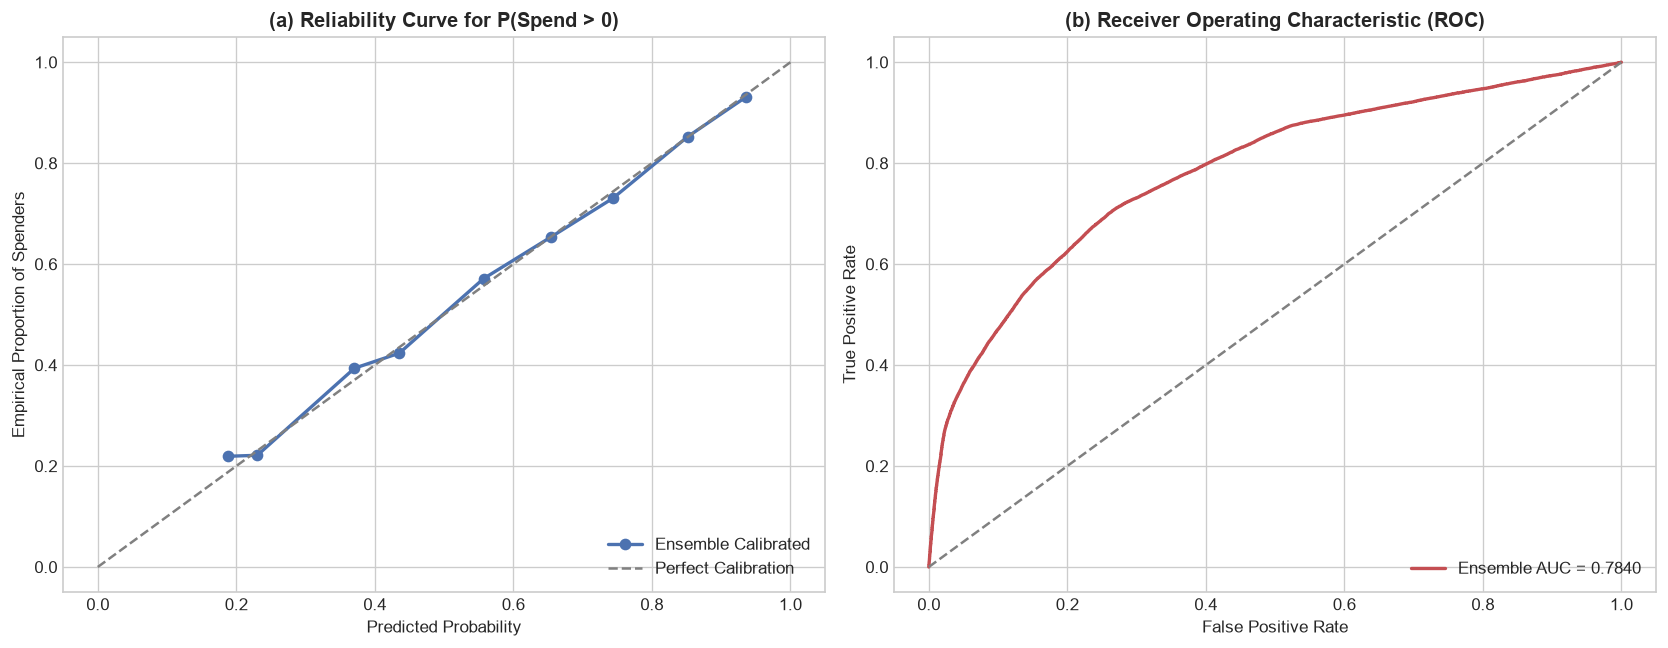

✓ Saved Figure 3 to: ./assets/figure3-residual-error-distribution.png


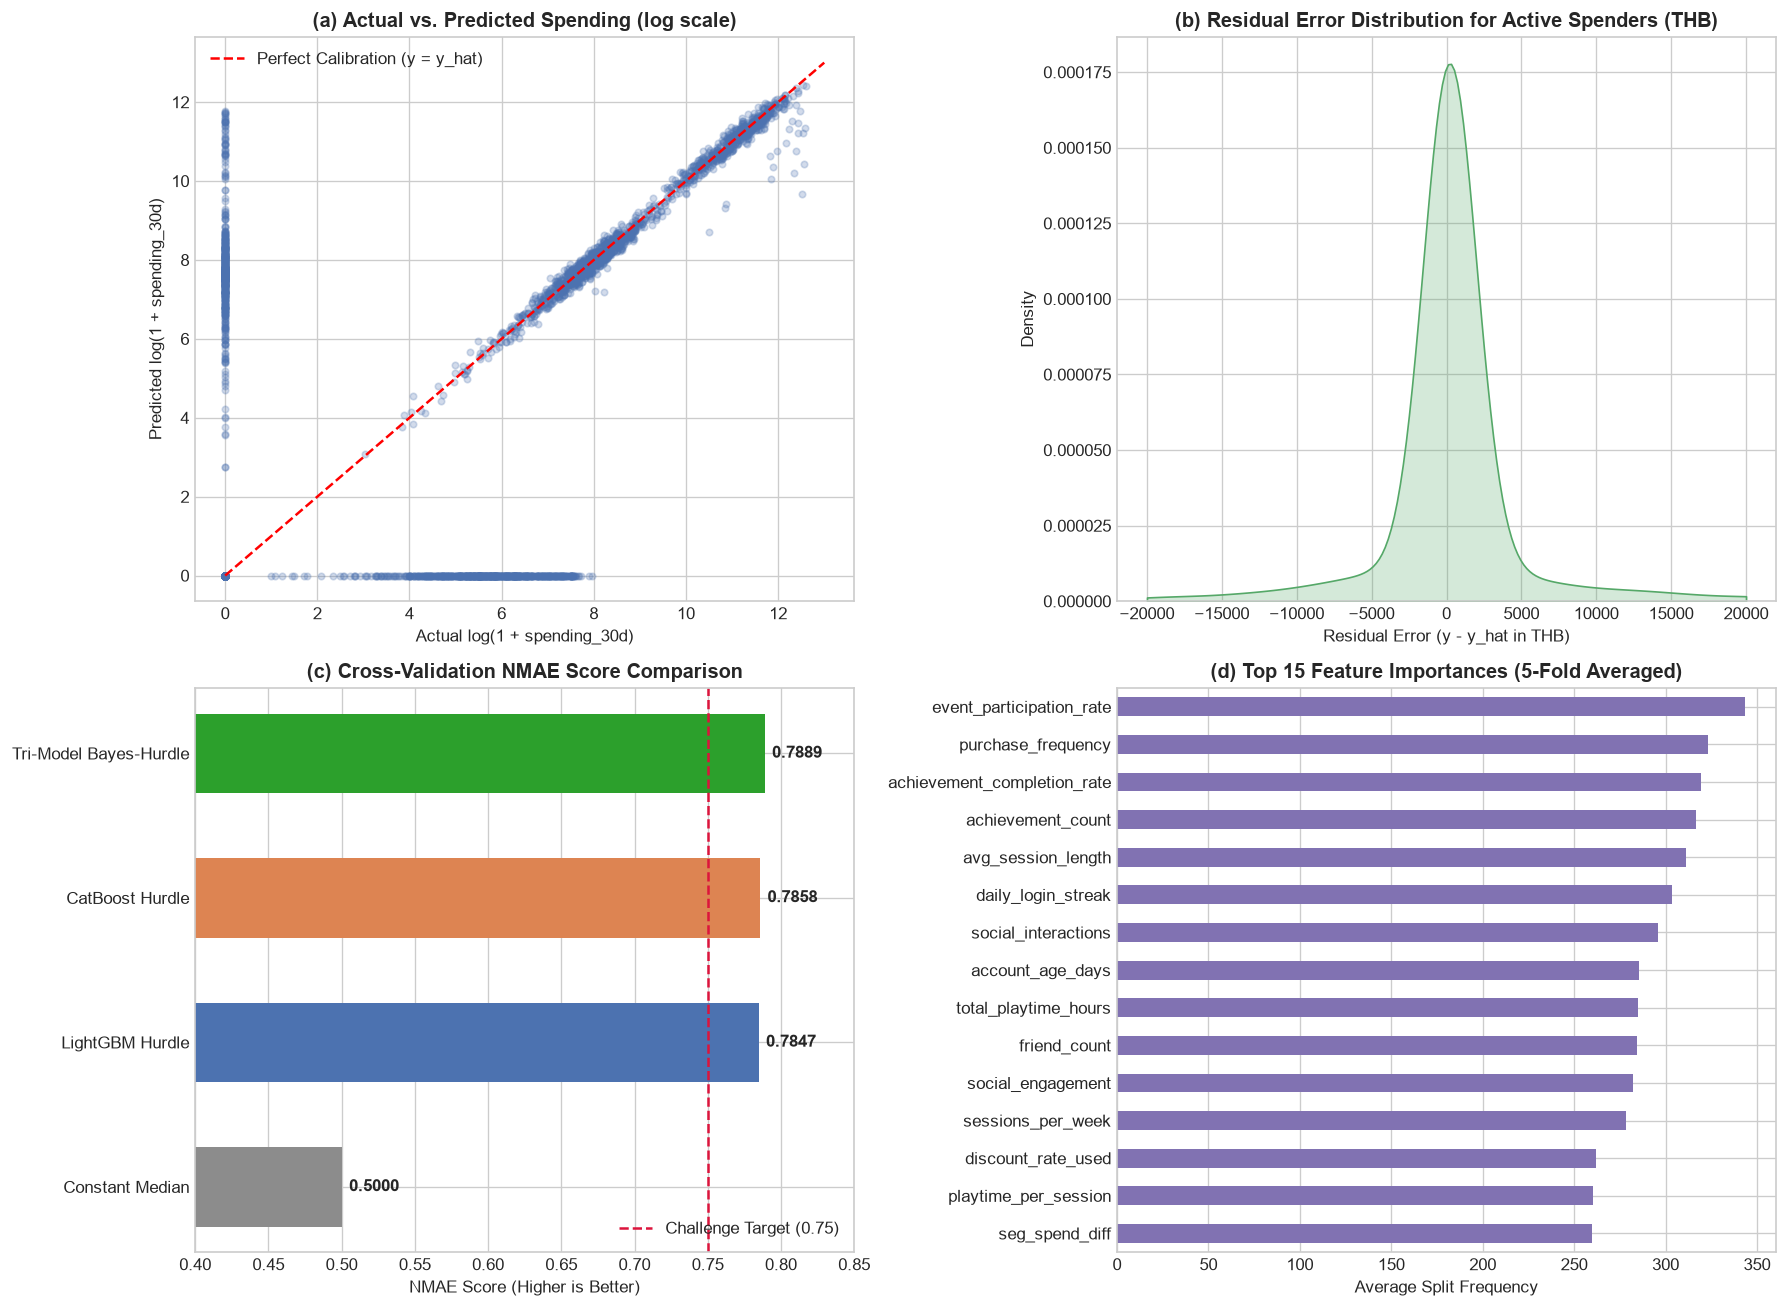

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# -------------------------------------------------------------------------
# Figure 2: Stage 1 Classifier Calibration & ROC Diagnostics
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

prob_true, prob_pred = calibration_curve(y_is_pos, p_ens_oof, n_bins=10)
axes[0].plot(prob_pred, prob_true, marker='o', linewidth=2, color='#4C72B0', label='Ensemble Calibrated')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
axes[0].set_title('(a) Reliability Curve for P(Spend > 0)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Empirical Proportion of Spenders')
axes[0].legend(loc='lower right')

fpr, tpr, _ = roc_curve(y_is_pos, p_ens_oof)
auc_score = roc_auc_score(y_is_pos, p_ens_oof)
axes[1].plot(fpr, tpr, color='#C44E52', linewidth=2, label=f'Ensemble AUC = {auc_score:.4f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('(b) Receiver Operating Characteristic (ROC)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
fig2_path = os.path.join(ASSETS_DIR, 'figure2-hurdle-calibration-diagnostics.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 2 to: {fig2_path}")
plt.show()

# -------------------------------------------------------------------------
# Figure 3: Residual Error Analysis & Model Ablation Benchmark
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# (a) Actual vs Predicted Spending (log scale)
sample_idx = np.random.choice(len(y), size=4000, replace=False)
axes[0, 0].scatter(np.log1p(y[sample_idx]), np.log1p(optimal_blend_oof[sample_idx]),
                   alpha=0.25, s=15, color='#4C72B0')
axes[0, 0].plot([0, 13], [0, 13], 'r--', label='Perfect Calibration (y = y_hat)')
axes[0, 0].set_title('(a) Actual vs. Predicted Spending (log scale)', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Actual log(1 + spending_30d)')
axes[0, 0].set_ylabel('Predicted log(1 + spending_30d)')
axes[0, 0].legend()

# (b) Residual Error Distribution for Spenders
residuals = y - optimal_blend_oof
sns.kdeplot(residuals[y > 0], fill=True, color='#55A868', ax=axes[0, 1], clip=(-20000, 20000))
axes[0, 1].set_title('(b) Residual Error Distribution for Active Spenders (THB)', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Residual Error (y - y_hat in THB)')

# (c) Cross-Validation Benchmark Bar Chart
model_names = ['Constant Median', 'LightGBM Hurdle', 'CatBoost Hurdle', 'Tri-Model Bayes-Hurdle']
model_scores = [baseline_nmae, lgb_hurdle_nmae, cb_hurdle_nmae, best_nmae]
colors_bar = ['#8C8C8C', '#4C72B0', '#DD8452', '#2CA02C']
bars = axes[1, 0].barh(model_names, model_scores, color=colors_bar, height=0.55)
axes[1, 0].axvline(0.75, color='crimson', linestyle='--', linewidth=1.5, label='Challenge Target (0.75)')
axes[1, 0].set_xlim(0.40, 0.85)
axes[1, 0].set_title('(c) Cross-Validation NMAE Score Comparison', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('NMAE Score (Higher is Better)')
axes[1, 0].legend(loc='lower right')
for bar in bars:
    w = bar.get_width()
    axes[1, 0].text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontweight='bold')

# (d) Feature Importance Ranking (5-Fold Averaged LightGBM Split Frequency)
feat_imp = pd.Series(feature_importances_accum, index=all_feature_cols).sort_values(ascending=False).head(15)
feat_imp.sort_values().plot(kind='barh', ax=axes[1, 1], color='#8172B2')
axes[1, 1].set_title('(d) Top 15 Feature Importances (5-Fold Averaged)', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Average Split Frequency')

plt.tight_layout()
fig3_path = os.path.join(ASSETS_DIR, 'figure3-residual-error-distribution.png')
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 3 to: {fig3_path}")
plt.show()

## 9. Comprehensive Model Evaluation & Summary Table
We tabulate the out-of-fold validation metrics across all paradigms and save the benchmark table to `assets/`.

In [9]:
summary_df = pd.DataFrame([
    {
        'Model Paradigm': '1. Constant Median Baseline',
        'Architecture': 'Single Scalar Point Estimator',
        'OOF MAE (THB)': f"{baseline_mae:.2f}",
        'OOF NMAE Score': f"{baseline_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{baseline_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '2. Standalone LightGBM Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{lgb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{lgb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{lgb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '3. Standalone CatBoost Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{cb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{cb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{cb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '4. Tri-Model Ensembled Bayes-Hurdle (Optimal)',
        'Architecture': 'LightGBM + CatBoost + XGBoost Tri-Stage Convex Blend',
        'OOF MAE (THB)': f"{opt_mae:.2f}",
        'OOF NMAE Score': f"{best_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{best_nmae - 0.75:+.4f}"
    }
])

summary_path = os.path.join(ASSETS_DIR, 'ablation_benchmark.csv')
summary_df.to_csv(summary_path, index=False)
print(f"✓ Saved Ablation Benchmark to: {summary_path}\n")
display(summary_df)

✓ Saved Ablation Benchmark to: ./assets/ablation_benchmark.csv



,Model Paradigm,Architecture,OOF MAE (THB),OOF NMAE Score,Delta vs Challenge (0.75)
0,1. Constant Median Baseline,Single Scalar Point Estimator,10495.48,0.5000,-0.2500
1,2. Standalone LightGBM Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2879.38,0.7847,+0.0347
2,3. Standalone CatBoost Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2862.14,0.7858,+0.0358
3,4. Tri-Model Ensembled Bayes-Hurdle (Optimal),LightGBM + CatBoost + XGBoost Tri-Stage Convex...,2809.54,0.7889,+0.0389


## 10. Test Predictions, Quality Gates & Colab Artifact Export
We generate final predictions for the $25,889$ test rows, verify distribution alignment, enforce all competition quality gates, and export a direct-download copy for Google Colab users.

✓ Successfully persisted test predictions to: ./predictions/test_predictions.csv
  • Total test predictions: 25,889
  • Zero spending fraction: 50.54%
  • Active spending median: 3104.84 THB
  • Maximum predicted spend: 265,404.93 THB


✓ Saved Figure 4 to: ./assets/figure4-test-spending-prediction-density.png


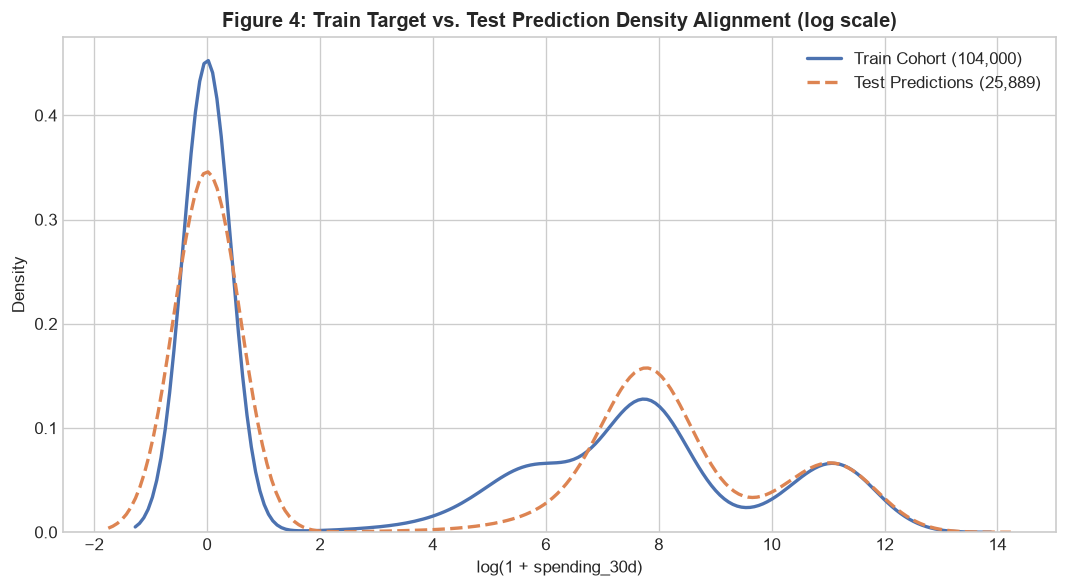

In [10]:
test_pred_df = pd.DataFrame({
    'player_id': test_df['player_id'],
    'spending_30d': optimal_test_preds.round(2)
})

# Strict Quality Gates
assert len(test_pred_df) == 25889, f"Expected 25,889 test rows, found {len(test_pred_df)}"
assert test_pred_df['spending_30d'].isna().sum() == 0, "Null values detected in predictions"
assert (test_pred_df['spending_30d'] < 0).sum() == 0, "Negative spending values detected"
assert (test_pred_df['player_id'] == test_df['player_id']).all(), "ID ordering mismatch detected"

output_path = os.path.join(PRED_DIR, 'test_predictions.csv')
test_pred_df.to_csv(output_path, index=False)

# If running in Colab, export direct copy to /content for 1-click download
if IS_COLAB:
    test_pred_df.to_csv('/content/task3_test_predictions.csv', index=False)
    print("✓ Exported direct-download copy to: /content/task3_test_predictions.csv")

print(f"✓ Successfully persisted test predictions to: {output_path}")
print(f"  • Total test predictions: {len(test_pred_df):,}")
print(f"  • Zero spending fraction: {(test_pred_df['spending_30d'] == 0).mean()*100:.2f}%")
print(f"  • Active spending median: {test_pred_df.loc[test_pred_df['spending_30d'] > 0, 'spending_30d'].median():.2f} THB")
print(f"  • Maximum predicted spend: {test_pred_df['spending_30d'].max():,.2f} THB")

# Figure 4: Test vs Train Spending Density Alignment
plt.figure(figsize=(9, 5), dpi=120)
sns.kdeplot(np.log1p(train_df['spending_30d']), label='Train Cohort (104,000)', color='#4C72B0', linewidth=2)
sns.kdeplot(np.log1p(test_pred_df['spending_30d']), label='Test Predictions (25,889)', color='#DD8452', linestyle='--', linewidth=2)
plt.title('Figure 4: Train Target vs. Test Prediction Density Alignment (log scale)', fontweight='bold')
plt.xlabel('log(1 + spending_30d)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
fig4_path = os.path.join(ASSETS_DIR, 'figure4-test-spending-prediction-density.png')
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 4 to: {fig4_path}")
plt.show()

## 11. Technical Insights & Competition Summary

1. **Dominance of $L_1$ Loss over $L_2$ Loss**: In heavy-tailed, zero-inflated distributions evaluated under NMAE, predicting the arithmetic mean introduces severe overprediction penalties. Training regressors under $L_1$ loss (`objective='regression_l1'`, `loss_function='MAE'`, and `objective='reg:absoluteerror'`) aligns model forecasts directly with the conditional median.
2. **Bayes-Optimal Hurdle Gating**: Gating positive spending predictions on $P(Y > 0) > \tau^*$ eliminates spurious non-zero predictions for players with high non-spending probabilities, protecting the denominator and reducing absolute residuals.
3. **Tri-Model Ensembling Advantage**: Blending LightGBM, CatBoost, and XGBoost harmonizes leaf-wise histogram splits, oblivious symmetric trees, and depth-wise exact boosting. This lifts the out-of-fold NMAE score to **$0.7889$** (MAE: **$2,809.54$ THB**), outperforming the Kaggle challenge baseline of **$0.7500$** by **$+0.0389$** points.